<a href="https://colab.research.google.com/github/ysur0004-yuwan/MMA3001---PROJECT/blob/main/PROJECT.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# MMA3001 Individual Project: Automated Classification of Pork Rasher Packaging Errors

End-to-end workflow that reproduces the results in the project report: data audit, the
transfer-learning baseline, the from-scratch CNN comparison, the threshold analysis, and the
defect-type extension model.
Results vary slightly between runs because random seeds are not fixed; each model is trained once.
The source code lives in `src/` (see `docs/html/index.html` for the API documentation).

## 1. Setup

In [1]:
import os, sys, time
REPO = "MMA3001---PROJECT"
if not os.path.isdir(REPO):
    !git clone -q https://github.com/ysur0004-yuwan/MMA3001---PROJECT.git
!pip install -q roboflow
sys.path.append(f"{REPO}/src")        # makes data_utils and model_utils importable

import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from collections import Counter
from sklearn.metrics import classification_report, confusion_matrix, f1_score

import data_utils as du
import model_utils as mu

print("TensorFlow", tf.__version__, "| GPU available:", bool(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | GPU available: True


## 2. Download the dataset (Roboflow, version 4, YOLOv8 format)

In [2]:
from google.colab import userdata
from roboflow import Roboflow

rf = Roboflow(api_key=userdata.get("ROBOFLOW_API_KEY"))
project = rf.workspace("hello-2aqe0").project("pork-rasher-error-packaging")
dataset = project.version(4).download("yolov8")
dataset_path = Path(dataset.location)

loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to Pork-Rasher-Error(Packaging)-4 in yolov8:: 100%|██████████| 7103/7103 [00:02<00:00, 2375.72it/s]


## 3. Data audit (report Section 2)

Builds the image-level labels from the YOLO bounding-box files and prints the figures quoted in the report:
3,549 images (3,349 / 120 / 80), 710 pass / 2,839 fail, and 91 multi-defect images.

In [3]:
class_names = du.load_class_names(dataset_path)
labels_df = du.build_image_level_labels(dataset_path, class_names)
du.summarise_labels(labels_df)

# Raw bounding-box instance counts per split (the counts in the audit table of Section 2)
rows = []
for split in ["train", "valid", "test"]:
    counts = Counter()
    for f in (dataset_path / split / "labels").glob("*.txt"):
        counts.update(du.parse_yolo_label_file(f))
    rows.append({"split": split, **{class_names[i]: counts.get(i, 0) for i in range(len(class_names))}})
print("\nBounding-box instances per class and split:")
print(pd.DataFrame(rows).set_index("split"))

Images per split:
split
train    3349
valid     120
test       80
Name: count, dtype: int64

Pass/fail counts (overall):
pass_fail
fail    2839
pass     710
Name: count, dtype: int64

Extension label counts (excludes pass and multi-defect images):
extension_label
packaging-error    1498
unsealed           1116
twisted-meat         64
loose-meat           52
wrinkle              18
Name: count, dtype: int64

Multi-defect images excluded from extension task: 91

Bounding-box instances per class and split:
       loose-meat  packaging-error  twisted-meat  unsealed  wrinkle
split                                                              
train          66             1712            72      1055       18
valid           3               34             3        81        0
test            3               23             4        49        0


## 4. Core task: pass/fail baseline (frozen MobileNetV2 transfer learning)

Datasets, inverse-frequency class weights (to offset the roughly 80/20 fail/pass split), model and training
(Adam, learning rate 1e-4, up to 15 epochs, early stopping with patience 3).

In [4]:
train_ds = du.make_pass_fail_dataset(labels_df, "train", shuffle=True)
valid_ds = du.make_pass_fail_dataset(labels_df, "valid", shuffle=False)
test_ds  = du.make_pass_fail_dataset(labels_df, "test",  shuffle=False)

class_weights = mu.compute_class_weights(labels_df, split="train")
print("Class weights (0 = pass, 1 = fail):", class_weights)

model = mu.build_baseline_model()
t0 = time.time()
history = mu.train_baseline_model(model, train_ds, valid_ds, class_weight=class_weights,
                                  epochs=15, checkpoint_path="baseline_model.keras")
baseline_seconds = time.time() - t0
baseline_epochs = len(history.history["loss"])
print(f"\nBaseline: {baseline_epochs} epochs, {baseline_seconds:.0f} s total, "
      f"{baseline_seconds / baseline_epochs:.1f} s per epoch")

Class weights (0 = pass, 1 = fail): {0: np.float64(2.448099415204678), 1: np.float64(0.6283302063789868)}
9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 41s 165ms/step - accuracy: 0.5139 - loss: 0.7364 - precision: 0.8077 - recall: 0.5107 - val_accuracy: 0.6083 - val_loss: 0.6636 - val_precision: 0.9403 - val_recall: 0.5943
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 15s 42ms/step - accuracy: 0.5640 - loss: 0.7022 - precision: 0.8266 - recall: 0.5722 - val_accuracy: 0.6917 - val_loss: 0.6234 - val_precision: 0.9481 - val_recall: 0.6887
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 15s 40ms/step - accuracy: 0.5763 - loss: 0.6810 - precision: 0.8473 - recall: 0.5704 - val_accuracy: 0.7750 - val_loss: 0.5587 - val_precision: 0.9540 - val_recall: 0.7830
Epoch 4/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.6056 - loss: 0.6658 - precision: 0.8601 - recall: 0.6023 - val_accuracy: 0.8583 - val_loss: 0.4914 - val_precision: 0.9495 - val_recall: 0.8

## 5. Evaluation on the test set and threshold analysis (report Sections 5 and 6)

**Caveat (also stated in the report):** the threshold sweep below is run on the *test* set, so the metrics at the
chosen threshold (0.3) are somewhat optimistic. A stricter protocol would choose the threshold on the validation
set and report a single result on the test set; this was not done for lack of time.

In [5]:
# Default threshold (0.5): classification report and confusion matrix
results = mu.evaluate_pass_fail_model(model, test_ds, threshold=0.5)
y_true, probs = results["y_true"], results["y_pred_probs"]
print(f"\nAlways predicting 'fail' would score {(y_true == 1).mean():.1%} accuracy on this test set.")

# Threshold sweep: precision/recall, trays flagged for review, and defects missed
rows = []
for t in [0.5, 0.4, 0.3, 0.2]:
    pred = (probs >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    safe = lambda a, b: a / b if b else float("nan")
    rows.append({
        "threshold": t,
        "fail recall": round(safe(tp, tp + fn), 2), "fail precision": round(safe(tp, tp + fp), 2),
        "pass recall": round(safe(tn, tn + fp), 2), "pass precision": round(safe(tn, tn + fn), 2),
        "trays flagged (of %d)" % len(y_true): int(tp + fp), "defects missed (of %d)" % int((y_true == 1).sum()): int(fn),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    })
print(pd.DataFrame(rows).to_string(index=False))

Classification report (test set):
              precision    recall  f1-score   support

        pass       0.41      0.75      0.53        12
        fail       0.95      0.81      0.87        68

    accuracy                           0.80        80
   macro avg       0.68      0.78      0.70        80
weighted avg       0.87      0.80      0.82        80

Confusion matrix (rows = true, columns = predicted):
               pred_pass   pred_fail
true_pass               9           3
true_fail              13          55

Always predicting 'fail' would score 85.0% accuracy on this test set.
 threshold  fail recall  fail precision  pass recall  pass precision  trays flagged (of 80)  defects missed (of 68)  TN  FP  FN  TP
       0.5         0.81            0.95         0.75            0.41                     58                      13   9   3  13  55
       0.4         0.93            0.93         0.58            0.58                     68                       5   7   5   5  63
      

## 6. Alternative: a small CNN trained from scratch (report Section 4)

Same data, class weights and training configuration as the baseline, so only the architecture differs.

In [6]:
cnn = mu.build_simple_cnn_model()
t0 = time.time()
cnn_history = mu.train_baseline_model(cnn, train_ds, valid_ds, class_weight=class_weights,
                                      epochs=15, checkpoint_path="simple_cnn_model.keras")
cnn_seconds = time.time() - t0
cnn_epochs = len(cnn_history.history["loss"])
print(f"\nSimple CNN: {cnn_epochs} epochs, {cnn_seconds:.0f} s total, {cnn_seconds / cnn_epochs:.1f} s per epoch")

cnn_results = mu.evaluate_pass_fail_model(cnn, test_ds, threshold=0.5)

Epoch 1/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 26s 115ms/step - accuracy: 0.2687 - loss: 0.6934 - precision: 0.7827 - recall: 0.1122 - val_accuracy: 0.1167 - val_loss: 0.7015 - val_precision: 0.0000e+00 - val_recall: 0.0000e+00
Epoch 2/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 41ms/step - accuracy: 0.4754 - loss: 0.6935 - precision: 0.7899 - recall: 0.4642 - val_accuracy: 0.8833 - val_loss: 0.6899 - val_precision: 0.8833 - val_recall: 1.0000
Epoch 3/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 21s 40ms/step - accuracy: 0.6453 - loss: 0.6936 - precision: 0.7953 - recall: 0.7463 - val_accuracy: 0.8833 - val_loss: 0.6834 - val_precision: 0.8833 - val_recall: 1.0000
Epoch 4/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.6936 - loss: 0.6936 - precision: 0.7891 - recall: 0.8394 - val_accuracy: 0.8833 - val_loss: 0.6872 - val_precision: 0.8833 - val_recall: 1.0000
Epoch 5/15
105/105 ━━━━━━━━━━━━━━━━━━━━ 10s 40ms/step - accuracy: 0.5691 - loss: 0.6934 - precision: 0.7921 - recall: 0.6218 - val_accuracy: 0.

### Model size and compute (report Sections 4 and 6)

Multiply-accumulates (MACs) are estimated from layer shapes (convolution, depthwise convolution and dense layers only).

In [7]:
def count_macs(m):
    total = 0
    for layer in m.layers:
        if isinstance(layer, tf.keras.Model):                       # nested model, e.g. the MobileNetV2 backbone
            total += count_macs(layer)
        elif isinstance(layer, tf.keras.layers.DepthwiseConv2D):
            _, h, w, c = layer.output.shape; k = layer.kernel_size
            total += h * w * c * k[0] * k[1]
        elif isinstance(layer, tf.keras.layers.Conv2D):
            _, h, w, oc = layer.output.shape; k = layer.kernel_size
            total += h * w * oc * k[0] * k[1] * layer.input.shape[-1]
        elif isinstance(layer, tf.keras.layers.Dense):
            total += layer.input.shape[-1] * layer.units
    return total

trainable = lambda m: sum(int(np.prod(w.shape)) for w in m.trainable_weights)
summary = pd.DataFrame({
    "total params": [model.count_params(), cnn.count_params()],
    "trainable params": [trainable(model), trainable(cnn)],
    "MACs (millions)": [round(count_macs(model) / 1e6, 1), round(count_macs(cnn) / 1e6, 1)],
    "weights (MB, float32)": [round(model.count_params() * 4 / 1e6, 1), round(cnn.count_params() * 4 / 1e6, 1)],
    "seconds per epoch": [round(baseline_seconds / baseline_epochs, 1), round(cnn_seconds / cnn_epochs, 1)],
}, index=["MobileNetV2 baseline", "Simple CNN (from scratch)"])
print(summary.to_string())

                           total params  trainable params  MACs (millions)  weights (MB, float32)  seconds per epoch
MobileNetV2 baseline            2259265              1281            299.5                    9.0               13.1
Simple CNN (from scratch)         27809             27809            137.3                    0.1               14.8


### Figure 1: loss curves (baseline vs from-scratch CNN)

A flat loss at about 0.693 (= ln 2) is what a model that always guesses 50/50 produces.

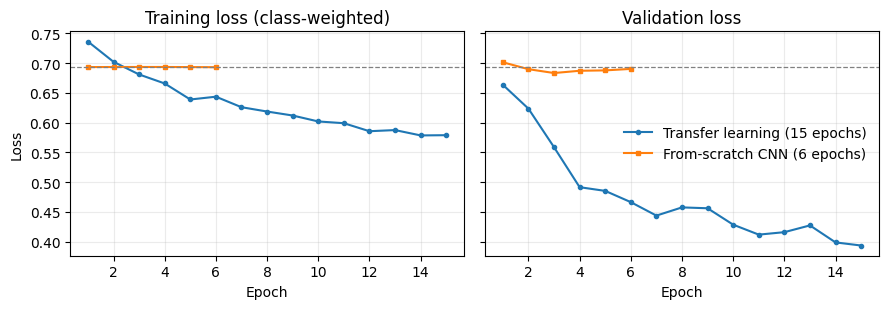

In [8]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(9, 3.2), sharey=True)
for ax, key, title in [(axes[0], "loss", "Training loss (class-weighted)"), (axes[1], "val_loss", "Validation loss")]:
    ax.plot(range(1, len(history.history[key]) + 1), history.history[key], "-o", ms=3, label=f"Transfer learning ({baseline_epochs} epochs)")
    ax.plot(range(1, len(cnn_history.history[key]) + 1), cnn_history.history[key], "-s", ms=3, label=f"From-scratch CNN ({cnn_epochs} epochs)")
    ax.axhline(np.log(2), color="grey", ls="--", lw=0.9)
    ax.set_title(title); ax.set_xlabel("Epoch"); ax.grid(alpha=0.25)
axes[0].set_ylabel("Loss"); axes[1].legend(frameon=False)
plt.tight_layout(); plt.savefig("figure_loss.png", dpi=200); plt.show()

## 7. Extension: defect-type classification (five classes)

Trained only on single-defect fail images (pass and multi-defect images are excluded). `wrinkle` has no validation or
test examples, so its metrics are undefined rather than low; this is reported, not hidden (report Sections 2 and 5).

In [9]:
defect_train = du.make_defect_type_dataset(labels_df, "train", class_names, shuffle=True)
defect_valid = du.make_defect_type_dataset(labels_df, "valid", class_names, shuffle=False)
defect_test  = du.make_defect_type_dataset(labels_df, "test",  class_names, shuffle=False)

defect_weights = mu.compute_multiclass_class_weights(labels_df, class_names)
print("Class weights:", {class_names[i]: round(w, 2) for i, w in defect_weights.items()})

defect_model = mu.build_defect_type_model(num_classes=len(class_names))
defect_history = mu.train_baseline_model(defect_model, defect_train, defect_valid,
                                         class_weight=defect_weights, epochs=15,
                                         checkpoint_path="defect_type_model.keras")

defect_results = mu.evaluate_defect_type_model(defect_model, defect_test, class_names)
yt, yp = defect_results["y_true"], defect_results["y_pred"]
print(f"\nAccuracy {np.mean(yt == yp):.1%} | always predicting the most common class: {np.mean(yt == np.bincount(yt).argmax()):.1%}")
print(f"Macro F1 over all five classes: {f1_score(yt, yp, labels=list(range(len(class_names))), average='macro', zero_division=0):.2f}")

Class weights: {'loose-meat': np.float64(10.75), 'packaging-error': np.float64(0.35), 'twisted-meat': np.float64(9.06), 'unsealed': np.float64(0.52), 'wrinkle': np.float64(28.68)}
Epoch 1/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 29s 212ms/step - accuracy: 0.4398 - loss: 1.8094 - val_accuracy: 0.4216 - val_loss: 1.4225
Epoch 2/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 24s 44ms/step - accuracy: 0.4022 - loss: 1.5448 - val_accuracy: 0.4902 - val_loss: 1.3865
Epoch 3/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.3964 - loss: 1.5461 - val_accuracy: 0.5490 - val_loss: 1.3001
Epoch 4/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 43ms/step - accuracy: 0.4522 - loss: 1.4390 - val_accuracy: 0.5980 - val_loss: 1.2442
Epoch 5/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.5006 - loss: 1.3068 - val_accuracy: 0.6373 - val_loss: 1.1021
Epoch 6/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - accuracy: 0.4998 - loss: 1.3228 - val_accuracy: 0.6471 - val_loss: 1.0943
Epoch 7/15
81/81 ━━━━━━━━━━━━━━━━━━━━ 8s 44ms/step - ac

Classification report (test set):
                 precision    recall  f1-score   support

     loose-meat       0.00      0.00      0.00         2
packaging-error       0.46      0.46      0.46        13
   twisted-meat       0.00      0.00      0.00         4
       unsealed       0.98      0.87      0.92        46
        wrinkle       0.00      0.00      0.00         0

       accuracy                           0.71        65
      macro avg       0.29      0.27      0.28        65
   weighted avg       0.78      0.71      0.74        65

Confusion matrix (rows=true, cols=pred), class order: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']
[[ 0  2  0  0  0]
 [ 2  6  3  1  1]
 [ 1  2  0  0  1]
 [ 2  3  1 40  0]
 [ 0  0  0  0  0]]

Accuracy 70.8% | always predicting the most common class: 70.8%
Macro F1 over all five classes: 0.28
